## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

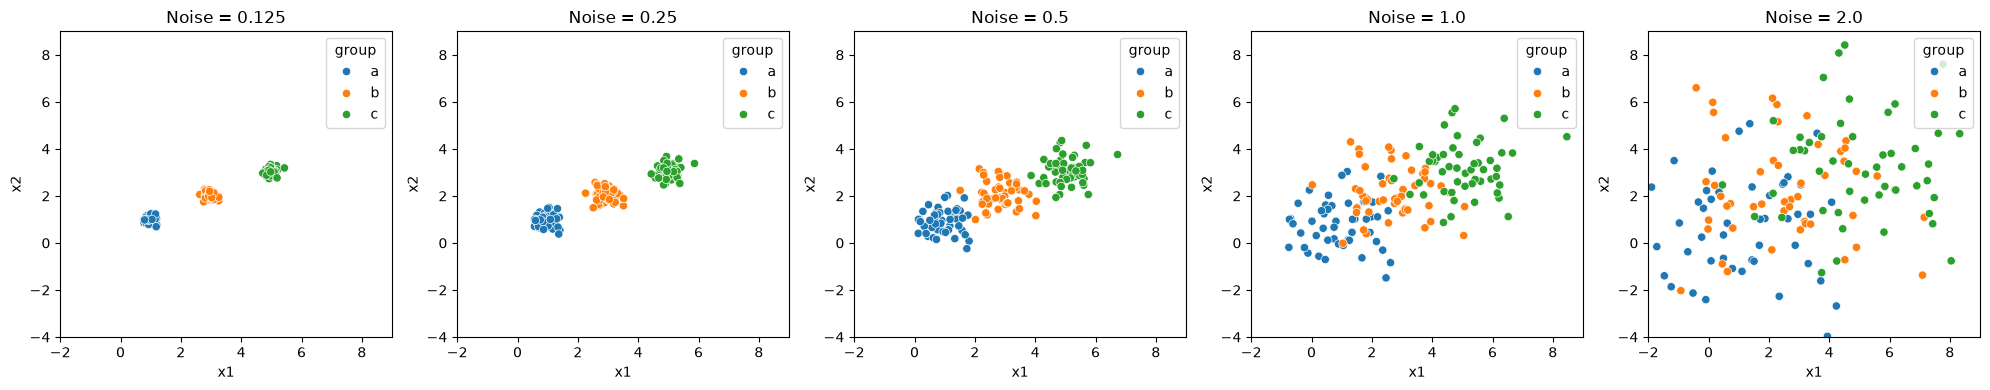

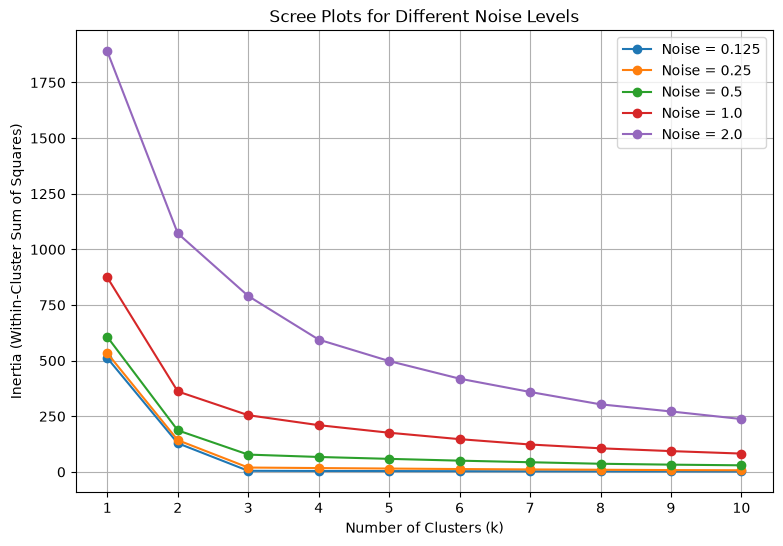

In [ ]:
# Your Phase 1 solution to the problem goes here.
#Q1
# QUESTION 1: 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])

    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})

    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noise_levels = [0.125, 0.25, 0.5, 1.0, 2.0]



# QUESTION 2: 


fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i in range(5):
    sns.scatterplot(data=datasets[i], x='x1', y='x2',
                    hue='group', ax=axes[i])
    axes[i].set_title('Noise = ' + str(noise_levels[i]))
    axes[i].set_xlim(-2, 9)
    axes[i].set_ylim(-4, 9)

plt.tight_layout()
plt.show()

# Explanation:

#The clusters become more spread out when the noise increases and they start to overlap.
#When the noice level are lower the three groups are much easier to tell apart.
#At higher noise levels, like 2.0, it is very difuclt to see where one group ends and 
#another begins.



# QUESTION 3: 

plt.figure(figsize=(9, 6))

for i in range(5):
    X = datasets[i][['x1', 'x2']]
    inertia_values = []

    for k in range(1, 11):
        model = KMeans(n_clusters=k, random_state=100, n_init=10)
        model.fit(X)
        inertia_values.append(model.inertia_)

    plt.plot(range(1, 11), inertia_values, marker='o',
             label='Noise = ' + str(noise_levels[i]))

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.title('Scree Plots for Different Noise Levels')
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.show()

# Explanation:

#A clear elbow at k = 3 is present at lower noise levels.
#When the noise level incrases it result in the elborw beocming less clear,
#this makes it harder to choose the optimal k value.
#Higher noise also has the impact of increasing inertia becuase points are more spread out
#At noise = 2.0, there is no obvious elbow at k =3.




# QUESTION 4: 

# The elbow is where adding more clusters stops making
# a big difference in reducing inertia. 
# With three oringal groups In this example going from 1 to 3 
# clusters has a large impact on reduces inertia when noise is low
#Becuase the main groups are already seperated after k = 3 adding more clusters 
#makes minimal improvments. This is why k = 3 is the right choice when the noise is low


Number of countries: 148
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object
       Spending (2020 USD)  Spending per Capita  \
count           148.000000           148.000000   
mean          13153.747670           268.264494   
std           68005.236120           430.434878   
min               8.622460             0.580129   
25%             204.877177            20.553464   
50%             959.535443            81.506703   
75%            5289.998320           326.267753   
max          778397.200000          2520.398541   

       Percent of Government Spending  Percent of GDP  
count                      148.000000      148.000000  
mean                         0.061510        0.019619  
std                          0.046207        0.015033  
min                          0.004896        0.000054  
25%                          0.031352        0.010413

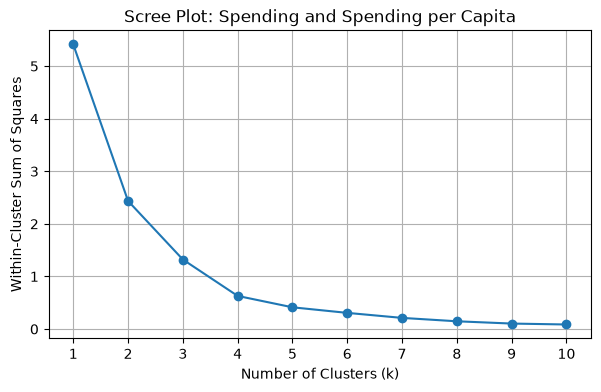

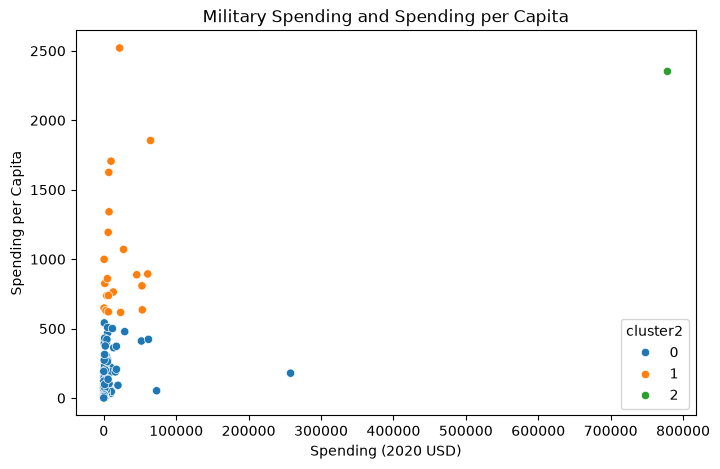

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster2                                                                   
0                      126.0    5943.346303  24858.961064       8.622460   
1                       21.0   19975.991473  21749.736747     405.790494   
2                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster2                                                               
0            162.761743     580.758315    3225.333414  257973.429834   
1           4980.428135    7269.880030   27300.894701   64558.400000   
2         778397.200000  778397.200000  778397.200000  778397.200000   

         Spending per Capita                                        \
                       count         mea

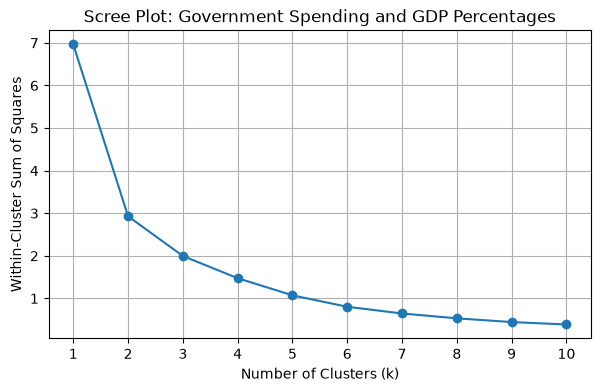

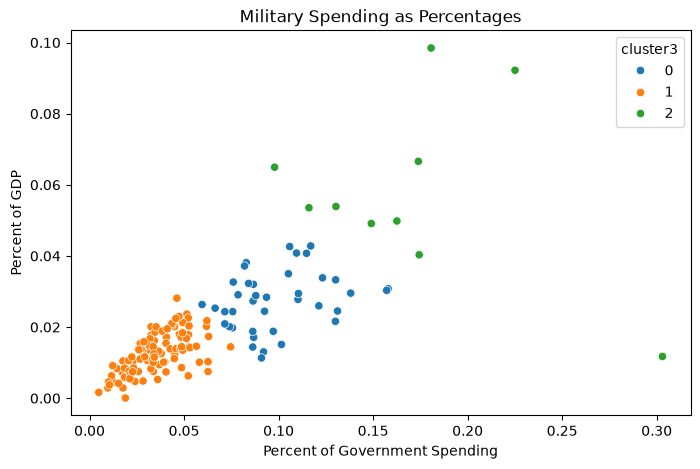

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster3                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  99.0  0.035777  0.014549  0.004896   
2                                  10.0  0.171289  0.058725  0.097882   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster3                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                      
               std       mi

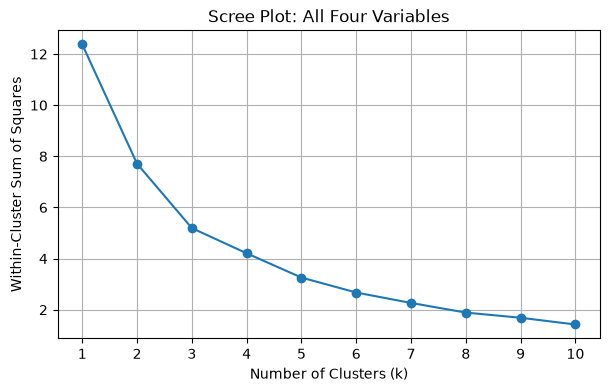

         Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster4                                                                  
0                      111.0    7086.472777   26479.379918     8.622460   
1                        6.0  147964.582042  309635.189564  6095.708713   
2                       31.0    8786.086602   17901.909108   162.373364   

                                                                  \
                  25%           50%           75%            max   
cluster4                                                           
0          130.010211    567.650747   3910.107493  257973.429834   
1         7700.424616  15897.570598  53872.942442  778397.200000   
2          467.787851   1404.787234   7739.166193   72937.064048   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...             

In [6]:
#Q2
# QUESTION 1:

df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')

df = df[df['Year'] == 2020].copy()
df = df.dropna()

columns = ['Spending (2020 USD)', 'Spending per Capita',
           'Percent of Government Spending', 'Percent of GDP']

print("Number of countries:", len(df))
print(df[columns].dtypes)
print(df[columns].describe())

# Explanation:
#filtering tro 2020 and removing all the msising values leaves me with 148 countires, 
#with all four vaiables being numeric so I do not need to change that. 



# QUESTION 2: 

cols2 = ['Spending (2020 USD)', 'Spending per Capita']

# Min-max normalization
X2 = df[cols2].copy()

for col in cols2:
    X2[col] = (X2[col] - X2[col].min()) / (X2[col].max() - X2[col].min())

# Scree plot
wcss2 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X2)
    wcss2.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss2, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('Scree Plot: Spending and Spending per Capita')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# K-means clustering
model2 = KMeans(n_clusters=3, random_state=100, n_init=10)
df['cluster2'] = model2.fit_predict(X2)

# Scatterplot
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=cols2[0], y=cols2[1],
                hue='cluster2', palette='tab10')
plt.title('Military Spending and Spending per Capita')
plt.show()

# Describe table
print(df.groupby('cluster2')[cols2].describe())

# United States and countries by cluster
print(df[df['Country'] == 'United States of America']
      [['Country', 'cluster2'] + cols2])

print(df.groupby('cluster2')['Country'].apply(list))

# Explanation:
#The elbow of the scree plot is around k = 3 which results in me chooosing 3 clsuters. 
#In cluser 0 is where most countries are which has a lower spending per capita, cluster 2 contains the
#coutnries with higher spending per capita, United states is the only country in here due to its high miltary spending. 



# QUESTION 3: 

cols3 = ['Percent of Government Spending', 'Percent of GDP']

# Min-max normalization
X3 = df[cols3].copy()

for col in cols3:
    X3[col] = (X3[col] - X3[col].min()) / (X3[col].max() - X3[col].min())

# Scree plot
wcss3 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X3)
    wcss3.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss3, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('Scree Plot: Government Spending and GDP Percentages')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# K-means clustering
model3 = KMeans(n_clusters=3, random_state=100, n_init=10)
df['cluster3'] = model3.fit_predict(X3)

# Scatterplot
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=cols3[0], y=cols3[1],
                hue='cluster3', palette='tab10')
plt.title('Military Spending as Percentages')
plt.show()

# Describe table
print(df.groupby('cluster3')[cols3].describe())

# United States and countries by cluster
print(df[df['Country'] == 'United States of America']
      [['Country', 'cluster3'] + cols3])

print(df.groupby('cluster3')['Country'].apply(list))

# Explanation:

#Again the scree plot leads me twoards 3 clusters but the elbow is less clear.
#cluster 1 has the lowest miltary spending percentages wise, 0 is in the middle, and 2
# has the higheset percentages, in this senario United States falls in 0 rather than being in alone in the previous example

#This explains that a coutnry can spend alot but becuase of other spending and gdp it might not have the highest percentage.



# QUESTION 4: 

X4 = df[columns].copy()

# Min-max normalization
for col in columns:
    X4[col] = (X4[col] - X4[col].min()) / (X4[col].max() - X4[col].min())

# Scree plot
wcss4 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X4)
    wcss4.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss4, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('Scree Plot: All Four Variables')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# K-means clustering
model4 = KMeans(n_clusters=3, random_state=100, n_init=10)
df['cluster4'] = model4.fit_predict(X4)

# Describe table
print(df.groupby('cluster4')[columns].describe())

# Compare clusters
print(pd.crosstab(df['cluster2'], df['cluster4']))
print(pd.crosstab(df['cluster3'], df['cluster4']))

# United States and countries by cluster
print(df[df['Country'] == 'United States of America']
      [['Country', 'cluster2', 'cluster3', 'cluster4']])

print(df.groupby('cluster4')['Country'].apply(list))

# Explanation:
# Looking at al four varaibles, I chose k =3 to compare for all the previous queiotns, 
# which amesk cluster 0 have the most countries with lower sepnding, cluster 1 have 6 countires with 
#a high spending per capita. and cluster 2 has countries that spend a large percentage on their military. 
#
#Unlike Quesitons 2, The us is no longer on its own cluster beucaes we are looking at more than just the total spending and spending per capita.



# QUESTION 5: 

# I think K-means was uself beucase it allowed me to see how countries are differnt in military spending
# Some might spend a large number overall, while others spend a large amount percentage wise compared
# to their use of resources, adn these tell different stories. However one note is that extreme values such as
#the country we live in, the US, can have an impact on the clusters, so the reuslts do not give a complete picture of miltary spending.



## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]